<a href="https://colab.research.google.com/github/22youl/BigData/blob/main/streaming_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **[과제4] 스트리밍 알고리즘 비교 실험**

**과제 목표**

- 대용량 데이터 스트림 환경에서 전체 데이터를 저장하지 않고 근사 계산을 수행하는 스트리밍 알고리즘을 구현하고, 정확도·메모리·처리시간 측면에서 알고리즘의 장단점을 비교한다.

**구현 대상 알고리즘**
- Bloom Filter
- Count-Min Sketch

**데이터셋**

- MovieLens 1M

# **1. 실험 설계**

**STEP 01. 데이터 준비**

- 데이터셋 다운로드 및 로드
- 스트림 형태로 한 줄씩 처리
- 전체 데이터를 한 번에 메모리에 올리지 않는 방식 권장

In [1]:
# Colab 기본 설치 라이브러리 사용 (별도 pip 설치 필요 없음)
import io
import os
import math
import time
import random
import sqlite3
import zipfile
import hashlib
import sys
from array import array
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)

# Colab에서 /content/ml-1m.zip 파일을 찾고, 없으면 업로드 창 실행
# 로컬 테스트 시 ML1M_ZIP_PATH 환경변수로 경로 지정 가능
ZIP_PATH = Path(os.environ.get("ML1M_ZIP_PATH", "/content/ml-1m.zip"))

if not ZIP_PATH.exists():
    try:
        from google.colab import files
        print("ml-1m.zip을 업로드하세요.")
        uploaded = files.upload()
        if "ml-1m.zip" not in uploaded:
            raise FileNotFoundError("업로드한 파일 목록에 ml-1m.zip이 없습니다.")
        ZIP_PATH = Path("/content/ml-1m.zip")
    except ImportError as exc:
        raise FileNotFoundError(f"ZIP 파일을 찾을 수 없습니다: {ZIP_PATH}") from exc

with zipfile.ZipFile(ZIP_PATH) as zf:
    names = zf.namelist()
    rating_files = [name for name in names if name.endswith("/ratings.dat") or name == "ratings.dat"]
    if len(rating_files) != 1:
        raise ValueError(f"ratings.dat 검색 결과를 확인하세요: {rating_files}")
    RATING_MEMBER = rating_files[0]
    info = zf.getinfo(RATING_MEMBER)

print(f"ZIP 파일: {ZIP_PATH.name}")
print(f"ratings 파일: {RATING_MEMBER}")
print(f"압축 해제 전 원본 크기: {info.file_size / 1024**2:.2f} MiB")
print("구분자: :: / 컬럼: UserID, MovieID, Rating, Timestamp")

ZIP 파일: ml-1m.zip
ratings 파일: ml-1m/ratings.dat
압축 해제 전 원본 크기: 23.45 MiB
구분자: :: / 컬럼: UserID, MovieID, Rating, Timestamp


In [2]:
def iter_ratings(zip_path=ZIP_PATH, member=RATING_MEMBER):
    """ZIP에서 평점 기록을 한 줄씩 읽는 generator (전체 RAM 로딩 X)."""
    with zipfile.ZipFile(zip_path) as zf:
        with zf.open(member, "r") as binary_file:
            with io.TextIOWrapper(binary_file, encoding="latin-1") as txt:
                for line_number, line in enumerate(txt, start=1):
                    parts = line.strip().split("::")
                    if len(parts) != 4:
                        raise ValueError(f"{line_number}번째 줄의 컬럼 수 오류: {parts}")
                    user_id, movie_id, rating, timestamp = map(int, parts)
                    yield user_id, movie_id, rating, timestamp

# 처음 5개만 가져와 구조 확인 (전체 데이터 메모리 적재하지 않음)
from itertools import islice
preview = list(islice(iter_ratings(), 5))
display(pd.DataFrame(preview, columns=["UserID", "MovieID", "Rating", "Timestamp"]))

,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


**STEP 02. 알고리즘 구현**

- Python 또는 PySpark 사용 (그외 다양한 도구 사용 가능)
- 선택한 알고리즘 2개 이상 직접 구현
- 라이브러리 사용 시 핵심 로직 설명 필수

**2-1. Bloom Filter**
- m비트 배열에 k개 해시 위치를 표시한다.
- 조회 결과가 **없음(False)**이면 실제로도 없는 원소이고, **있음(True)**이면 오탐(False Positive) 가능성이 있다.
- 정상적으로 추가한 원소를 조회할 때 False Negative는 없다.
- 해시 위치는 안정적(실행 중 값이 변하지 않음)인 BLAKE2b의 128비트 결과에서 두 64비트 값으로 나누어 double hashing한다. 배열은 bytearray로 구현한다.

**2-2. Count-Min Sketch**
- depth개의 행, width개의 열로 구성된 비음수 카운터 배열을 사용한다.
- 평점 기록 하나를 읽을 때 영화 ID를 각 행의 해시 위치에 반영한다.
- 추정 빈도는 각 행의 카운터 가운데 최솟값이다.
- 해시 충돌 때문에 추정값이 실제 빈도보다 커질 수 있다. 32비트 카운터가 오버플로하지 않는 데이터 범위에서 과소 추정은 발생하지 않는다.
- Python 리스트 대신 array('I')를 사용해 카운터 배열의 메모리를 절약한다.

In [3]:
def hash_pair(key):
    """같은 키에 항상 같은 두 64비트 정수를 반환."""
    digest = hashlib.blake2b(str(key).encode("utf-8"), digest_size=16).digest()
    h1 = int.from_bytes(digest[:8], "little")
    h2 = int.from_bytes(digest[8:], "little") | 1  # 0이 아니면서 홀수
    return h1, h2


class BloomFilter:
    def __init__(self, expected_items, bits_per_item=10, num_hashes=7):
        if expected_items <= 0 or bits_per_item <= 0 or num_hashes <= 0:
            raise ValueError("expected_items, bits_per_item, num_hashes 모두 양수여야 합니다.")
        self.expected_items = int(expected_items)
        self.bits_per_item = float(bits_per_item)
        self.bit_count = math.ceil(self.expected_items * self.bits_per_item)
        self.num_hashes = int(num_hashes)
        self.bits = bytearray((self.bit_count + 7) // 8)

    def add(self, key):
        h1, h2 = hash_pair(key)
        for i in range(self.num_hashes):
            position = (h1 + i * h2) % self.bit_count
            self.bits[position // 8] |= 1 << (position % 8)

    def contains(self, key):
        h1, h2 = hash_pair(key)
        for i in range(self.num_hashes):
            position = (h1 + i * h2) % self.bit_count
            if not (self.bits[position // 8] & (1 << (position % 8))):
                return False
        return True

    def memory_bytes(self):
        # 자체 자료구조의 실측 크기(객체 + 바이트 배열). 입력/SQLite 제외.
        return sys.getsizeof(self) + sys.getsizeof(self.bits)


class CountMinSketch:
    def __init__(self, width=1024, depth=5):
        if width <= 0 or depth <= 0:
            raise ValueError("width, depth 모두 양수여야 합니다.")
        self.width = int(width)
        self.depth = int(depth)
        self.table = [array("I", [0]) * self.width for _ in range(self.depth)]

    def add(self, key, count=1):
        if count <= 0:
            raise ValueError("count는 양수여야 합니다.")
        h1, h2 = hash_pair(key)
        for i, row in enumerate(self.table):
            col = (h1 + i * h2) % self.width
            row[col] += count

    def estimate(self, key):
        h1, h2 = hash_pair(key)
        return min(row[(h1 + i * h2) % self.width]
                   for i, row in enumerate(self.table))

    def memory_bytes(self):
        # 리스트/배열 객체 비용 포함. 공유된 입력 데이터 및 검사 용도 DB 제외.
        return sys.getsizeof(self) + sys.getsizeof(self.table) + sum(
            sys.getsizeof(row) for row in self.table
        )


# 간단한 자체 검증
bf_test = BloomFilter(expected_items=100, bits_per_item=12, num_hashes=5)
bf_test.add("1:10")
assert bf_test.contains("1:10")

cms_test = CountMinSketch(width=128, depth=3)
cms_test.add(10)
cms_test.add(10)
cms_test.add(20)
assert cms_test.estimate(10) >= 2
assert cms_test.estimate(20) >= 1
print("Bloom Filter / Count-Min Sketch 기본 동작 테스트 통과")

Bloom Filter / Count-Min Sketch 기본 동작 테스트 통과


**STEP 03. Ground Truth 계산**
- 정확한 결과를 별도로 계산
- 스트리밍 알고리즘 결과와 비교

평가 기준과 스트리밍 처리 결과를 분리한다.
- Bloom Filter 정답: (UserID, MovieID) 쌍이 존재하는지 SQLite의 디스크 기반 정확한 인덱스로 확인한다. 모든 쌍을 Python set에 보관하지 않는다.
- Count-Min Sketch 정답: 영화별 실제 평점 횟수를 Counter로 구한다. 영화 ID별 집계 결과만 저장하므로 데이터 100만 행 전체를 저장하는 것은 아니다.
- 평가용 양성(존재) 샘플: 스트림에서 Reservoir Sampling으로 10,000개를 확보한다.
- 평가용 음성(부재) 샘플: 실제 출현한 사용자 ID와 영화 ID에서 후보를 만들고 SQLite로 없음을 검사한 뒤 10,000개를 확보한다.
- 중요: SQLite는 정답 검증을 위한 별도 장치로 디스크에 전체 쌍을 보존한다. Bloom Filter/Count-Min Sketch 자체는 이 DB를 참조하지 않고 입력 스트림만 받아 갱신한다. 실험의 메모리 비교 값에도 SQLite 저장 공간은 포함하지 않는다.

In [4]:
DB_PATH = Path(os.environ.get("ML1M_GT_DB_PATH", "/content/ml1m_ground_truth.sqlite"))
DB_PATH.parent.mkdir(parents=True, exist_ok=True)
if DB_PATH.exists():
    DB_PATH.unlink()  # 노트북 재실행 시 동일하게 재생성

conn = sqlite3.connect(str(DB_PATH))
conn.execute("PRAGMA journal_mode=OFF")  # 재생성 가능한 실험용 DB이므로 기록 비용 절약
conn.execute("PRAGMA synchronous=OFF")
conn.execute("PRAGMA cache_size=-20000")  # DB 페이지 캐시는 약 20 MiB로 제한
conn.execute("""
    CREATE TABLE rating_pairs (
        user_id INTEGER NOT NULL,
        movie_id INTEGER NOT NULL,
        PRIMARY KEY (user_id, movie_id)
    ) WITHOUT ROWID
""")

movie_truth = Counter()
user_ids = set()
positive_samples = []
POSITIVE_SAMPLE_SIZE = 10_000
NEGATIVE_SAMPLE_SIZE = 10_000
rng = random.Random(SEED)

record_count = 0
batch = []
t0 = time.perf_counter()

for user_id, movie_id, _, _ in iter_ratings():
    record_count += 1
    movie_truth[movie_id] += 1
    user_ids.add(user_id)
    pair = (user_id, movie_id)
    batch.append(pair)

    # 균등 Reservoir Sampling: 전체 기록을 RAM에 보유하지 않음
    if len(positive_samples) < POSITIVE_SAMPLE_SIZE:
        positive_samples.append(pair)
    else:
        j = rng.randrange(record_count)
        if j < POSITIVE_SAMPLE_SIZE:
            positive_samples[j] = pair

    if len(batch) >= 10_000:
        conn.executemany(
            "INSERT OR IGNORE INTO rating_pairs(user_id, movie_id) VALUES (?, ?)", batch
        )
        batch.clear()

if batch:
    conn.executemany(
        "INSERT OR IGNORE INTO rating_pairs(user_id, movie_id) VALUES (?, ?)", batch
    )
conn.commit()

unique_pair_count = conn.execute("SELECT COUNT(*) FROM rating_pairs").fetchone()[0]
assert sum(movie_truth.values()) == record_count

# 실제 등장하는 사용자/영화 ID 조합 중 평가용 부재 샘플 확보
available_users = sorted(user_ids)
available_movies = sorted(movie_truth)
negative_samples = []
negative_seen = set()
lookup = conn.cursor()

while len(negative_samples) < NEGATIVE_SAMPLE_SIZE:
    candidate = (rng.choice(available_users), rng.choice(available_movies))
    if candidate in negative_seen:
        continue
    exists = lookup.execute(
        "SELECT 1 FROM rating_pairs WHERE user_id=? AND movie_id=?", candidate
    ).fetchone()
    if exists is None:
        negative_seen.add(candidate)
        negative_samples.append(candidate)

gt_time = time.perf_counter() - t0
assert all(lookup.execute(
    "SELECT 1 FROM rating_pairs WHERE user_id=? AND movie_id=?", x
).fetchone() is not None for x in positive_samples)

print(f"전체 평점 기록 수: {record_count:,}")
print(f"고유 (사용자, 영화) 쌍 수: {unique_pair_count:,}")
print(f"영화 종류 수(실제 평점 기록 기준): {len(movie_truth):,}")
print(f"사용자 종류 수: {len(user_ids):,}")
print(f"Ground Truth 구축 및 샘플링: {gt_time:.2f}초")
print(f"정답 DB 디스크 크기: {DB_PATH.stat().st_size / 1024**2:.2f} MiB (근사 알고리즘 메모리 제외)")
print(f"검사 표본: 양성 {len(positive_samples):,}건 / 음성 {len(negative_samples):,}건")

display(pd.DataFrame(movie_truth.most_common(10), columns=["MovieID", "실제 빈도"]))

전체 평점 기록 수: 1,000,209
고유 (사용자, 영화) 쌍 수: 1,000,209
영화 종류 수(실제 평점 기록 기준): 3,706
사용자 종류 수: 6,040
Ground Truth 구축 및 샘플링: 15.18초
정답 DB 디스크 크기: 10.84 MiB (근사 알고리즘 메모리 제외)
검사 표본: 양성 10,000건 / 음성 10,000건


,MovieID,실제 빈도
0,2858,3428
1,260,2991
2,1196,2990
3,1210,2883
4,480,2672
5,2028,2653
6,589,2649
7,2571,2590
8,1270,2583
9,593,2578


**STEP 04. 성능 분석 항목**

| 항목 | Bloom Filter | Count-Min Sketch |
|---|---|---|
| 정확도 | FPR=FP/실제 음성 수, FNR=FN/실제 양성 수, 표본 정확도, 이론 FPR | MAE=오차 절댓값 평균, MAPE=평균 상대오차, WAPE=총 절대오차/실제 총합, 중앙값 상대오차, 최대 상대오차, 정확 일치율 |
| 메모리 | Bloom 객체 + `bytearray`의 `sys.getsizeof()` | CMS 객체 + 리스트 + `array('I')`의 `sys.getsizeof()` 합계 |
| 시간 | ZIP 읽기·파싱 + 항목 삽입 시간, 평가 질의 시간 별도 | ZIP 읽기·파싱 + 항목 삽입 시간, 평가 질의 시간 별도 |
| 처리량 | 전체 입력 레코드 수 / 삽입 스트림 처리시간 | 동일 |

In [5]:
def bench_bloom(bits_per_item, num_hashes, label):
    bloom = BloomFilter(
        expected_items=unique_pair_count,
        bits_per_item=bits_per_item,
        num_hashes=num_hashes,
    )
    start = time.perf_counter()
    processed = 0
    for uid, mid, _, _ in iter_ratings():
        bloom.add(f"{uid}:{mid}")
        processed += 1
    stream_sec = time.perf_counter() - start
    assert processed == record_count

    query_start = time.perf_counter()
    tp = sum(bloom.contains(f"{u}:{m}") for u, m in positive_samples)
    fp = sum(bloom.contains(f"{u}:{m}") for u, m in negative_samples)
    query_sec = time.perf_counter() - query_start
    fn = len(positive_samples) - tp
    tn = len(negative_samples) - fp

    return {
        "설정": label,
        "bits/item": bits_per_item,
        "k": num_hashes,
        "비트 수": bloom.bit_count,
        "FPR": fp / len(negative_samples),
        "이론 FPR": (1 - math.exp(-num_hashes * unique_pair_count / bloom.bit_count)) ** num_hashes,
        "FNR": fn / len(positive_samples),
        "정확도": (tp + tn) / (len(positive_samples) + len(negative_samples)),
        "FP 개수": fp,
        "FN 개수": fn,
        "메모리(MiB)": bloom.memory_bytes() / 1024**2,
        "처리시간(초)": stream_sec,
        "평가시간(초)": query_sec,
        "처리량(건/초)": processed / stream_sec,
    }


def bench_cms(width, depth, label):
    sketch = CountMinSketch(width=width, depth=depth)
    start = time.perf_counter()
    processed = 0
    for _, movie_id, _, _ in iter_ratings():
        sketch.add(movie_id)
        processed += 1
    stream_sec = time.perf_counter() - start
    assert processed == record_count

    query_start = time.perf_counter()
    real = np.array([movie_truth[movie] for movie in available_movies], dtype=np.float64)
    estim = np.array([sketch.estimate(movie) for movie in available_movies], dtype=np.float64)
    query_sec = time.perf_counter() - query_start

    absolute_errors = np.abs(estim - real)
    relative_errors = absolute_errors / real
    # 범위 내 unsigned 정수 카운터, Count-Min Sketch는 과소 추정하지 않음
    assert np.all(estim >= real)

    return {
        "설정": label,
        "width": width,
        "depth": depth,
        "MAE(건)": float(np.mean(absolute_errors)),
        "WAPE(%)": float(np.sum(absolute_errors) / np.sum(real) * 100),
        "중앙값 상대오차(%)": float(np.median(relative_errors) * 100),
        "MAPE(%)": float(np.mean(relative_errors) * 100),
        "최대 상대오차(%)": float(np.max(relative_errors) * 100),
        "정확 일치율(%)": float(np.mean(estim == real) * 100),
        "메모리(MiB)": sketch.memory_bytes() / 1024**2,
        "처리시간(초)": stream_sec,
        "평가시간(초)": query_sec,
        "처리량(건/초)": processed / stream_sec,
    }

**STEP 05. 파라미터 비교 실험**

- Bloom Filter: 비트 배열 크기를 6 / 10 / 14 bits/item으로 바꾸되 k=7을 고정해 비교하고, 10 bits/item일 때 k=3 / 5 / 7을 비교한다. k ≈ (m/n) ln 2가 흔히 사용하는 이론적 기준이다.

- Count-Min Sketch: depth=5를 고정하고 width=512 / 1024 / 2048 / 4096을 비교한다. 이어서 width=1024를 고정하고 depth=3 / 5를 비교한다.

In [6]:
# 가장 기본인 bits/item=10, k=7 과 width=1024, depth=5를 기준 설정으로 사용
bloom_configs = [
    (6, 7, "BF: 6bit / k7"),
    (10, 3, "BF: 10bit / k3"),
    (10, 5, "BF: 10bit / k5"),
    (10, 7, "BF: 10bit / k7 [기준]"),
    (14, 7, "BF: 14bit / k7"),
]

bloom_results = []
for bpi, k, label in bloom_configs:
    row = bench_bloom(bpi, k, label)
    bloom_results.append(row)
    print(f"완료: {label:<24} | FPR {row['FPR']:.4%} | "
          f"메모리 {row['메모리(MiB)']:.3f} MiB | {row['처리시간(초)']:.2f}초")

bf_df = pd.DataFrame(bloom_results)
assert (bf_df["FNR"] == 0).all(), "Bloom Filter에서 FN이 발생함. 구현 확인 필요!"
display(bf_df.round(4))

완료: BF: 6bit / k7            | FPR 7.5100% | 메모리 0.716 MiB | 7.15초
완료: BF: 10bit / k3           | FPR 1.7800% | 메모리 1.192 MiB | 6.41초
완료: BF: 10bit / k5           | FPR 0.8500% | 메모리 1.192 MiB | 7.20초
완료: BF: 10bit / k7 [기준]      | FPR 0.8000% | 메모리 1.192 MiB | 8.09초
완료: BF: 14bit / k7           | FPR 0.1200% | 메모리 1.669 MiB | 7.25초


,설정,bits/item,k,비트 수,FPR,이론 FPR,FNR,정확도,FP 개수,FN 개수,메모리(MiB),처리시간(초),평가시간(초),처리량(건/초)
0,BF: 6bit / k7,6,7,6001254,0.0751,0.0734,0.0,0.9624,751,0,0.7155,7.1469,0.0781,139950.0340
1,BF: 10bit / k3,10,3,10002090,0.0178,0.0174,0.0,0.9911,178,0,1.1924,6.4106,0.0605,156023.1504
2,BF: 10bit / k5,10,5,10002090,0.0085,0.0094,0.0,0.9958,85,0,1.1924,7.1998,0.0709,138921.4080
3,BF: 10bit / k7 [기준],10,7,10002090,0.0080,0.0082,0.0,0.9960,80,0,1.1924,8.0867,0.0752,123685.5568
4,BF: 14bit / k7,14,7,14002926,0.0012,0.0015,0.0,0.9994,12,0,1.6694,7.2470,0.1327,138017.7156


In [7]:
cms_configs = [
    (512, 5, "CMS: w512 / d5"),
    (1024, 3, "CMS: w1024 / d3"),
    (1024, 5, "CMS: w1024 / d5 [기준]"),
    (2048, 5, "CMS: w2048 / d5"),
    (4096, 5, "CMS: w4096 / d5"),
]

cms_results = []
for width, depth, label in cms_configs:
    row = bench_cms(width, depth, label)
    cms_results.append(row)
    print(f"완료: {label:<25} | MAPE {row['MAPE(%)']:.2f}% | "
          f"메모리 {row['메모리(MiB)']:.3f} MiB | {row['처리시간(초)']:.2f}초")

cms_df = pd.DataFrame(cms_results)
display(cms_df.round(4))

완료: CMS: w512 / d5            | MAPE 5051.20% | 메모리 0.010 MiB | 6.23초
완료: CMS: w1024 / d3           | MAPE 2296.57% | 메모리 0.012 MiB | 4.52초
완료: CMS: w1024 / d5 [기준]      | MAPE 1348.80% | 메모리 0.020 MiB | 6.81초
완료: CMS: w2048 / d5           | MAPE 222.32% | 메모리 0.040 MiB | 5.71초
완료: CMS: w4096 / d5           | MAPE 15.33% | 메모리 0.079 MiB | 7.18초


,설정,width,depth,MAE(건),WAPE(%),중앙값 상대오차(%),MAPE(%),최대 상대오차(%),정확 일치율(%),메모리(MiB),처리시간(초),평가시간(초),처리량(건/초)
0,CMS: w512 / d5,512,5,727.9115,269.7076,501.7663,5051.2003,360300.0,0.1619,0.0103,6.2310,0.0158,160521.7619
1,CMS: w1024 / d3,1024,3,343.0521,127.1085,162.0364,2296.5698,175600.0,7.6902,0.0121,4.5232,0.0132,221129.2016
2,CMS: w1024 / d5 [기준],1024,5,199.3705,73.8713,86.6948,1348.8033,94900.0,12.5202,0.0201,6.8120,0.0155,146830.9501
3,CMS: w2048 / d5,2048,5,35.0575,12.9896,0.0000,222.3186,40400.0,58.9045,0.0396,5.7100,0.0194,175169.4204
4,CMS: w4096 / d5,4096,5,3.3805,1.2525,0.0000,15.3345,12550.0,92.5256,0.0787,7.1788,0.0159,139329.0984


**5-1. Bloom Filter 파라미터 영향 그래프**

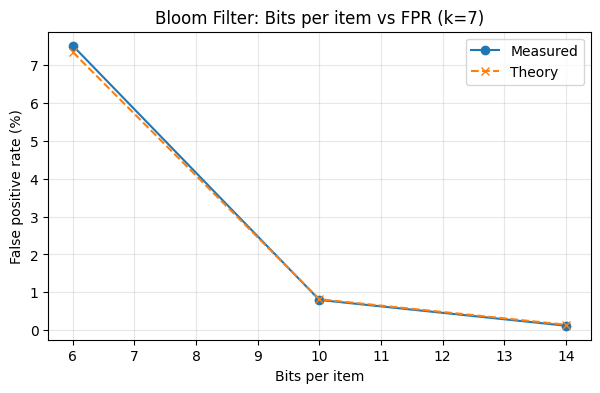

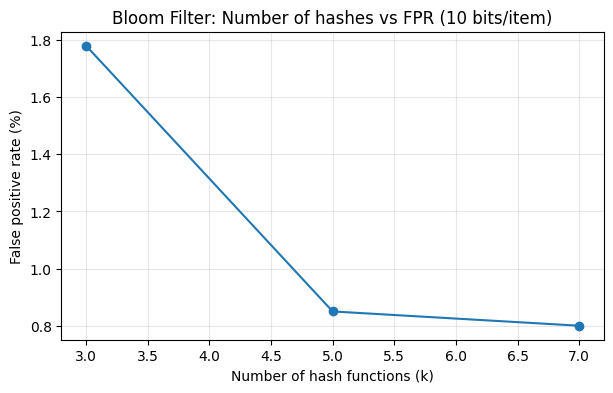

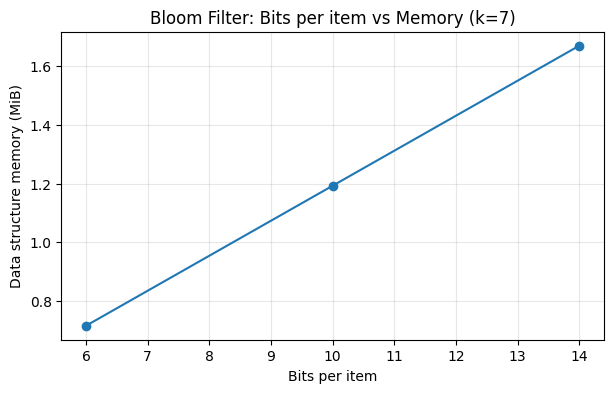

In [8]:
# 비트 수와 k 비교를 분리해 한 변수를 고정하고 비교
bf_size = bf_df[bf_df["k"] == 7].sort_values("bits/item")
bf_hash = bf_df[bf_df["bits/item"] == 10].sort_values("k")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bf_size["bits/item"], bf_size["FPR"] * 100, marker="o", label="Measured")
ax.plot(bf_size["bits/item"], bf_size["이론 FPR"] * 100, linestyle="--", marker="x", label="Theory")
ax.legend()
ax.set(title="Bloom Filter: Bits per item vs FPR (k=7)",
       xlabel="Bits per item", ylabel="False positive rate (%)")
ax.grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bf_hash["k"], bf_hash["FPR"] * 100, marker="o")
ax.set(title="Bloom Filter: Number of hashes vs FPR (10 bits/item)",
       xlabel="Number of hash functions (k)", ylabel="False positive rate (%)")
ax.grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bf_size["bits/item"], bf_size["메모리(MiB)"], marker="o")
ax.set(title="Bloom Filter: Bits per item vs Memory (k=7)",
       xlabel="Bits per item", ylabel="Data structure memory (MiB)")
ax.grid(True, alpha=0.3)
plt.show()

**5-2. Count-Min Sketch 파라미터 영향 그래프**

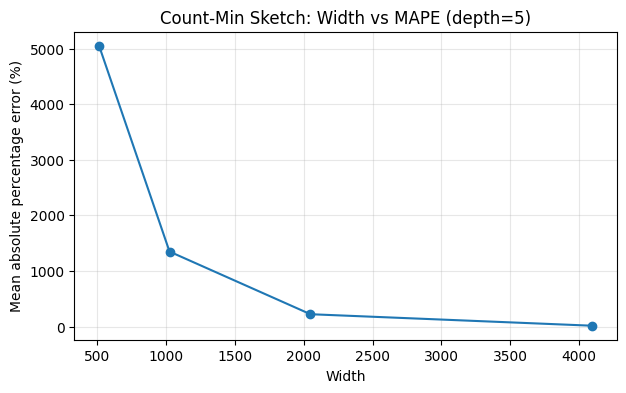

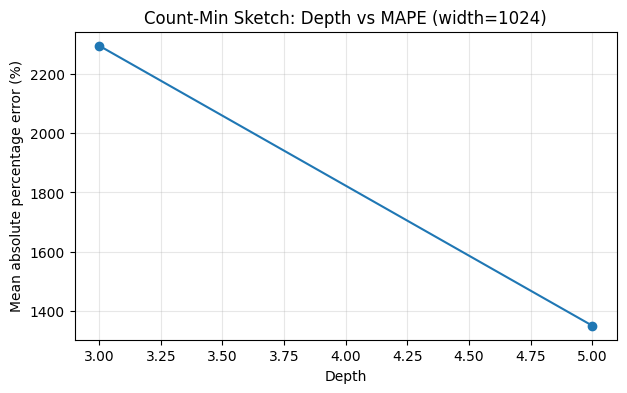

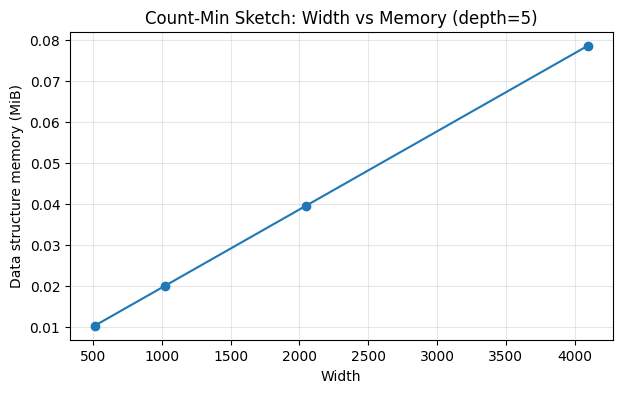

In [9]:
cms_width = cms_df[cms_df["depth"] == 5].sort_values("width")
cms_depth = cms_df[cms_df["width"] == 1024].sort_values("depth")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cms_width["width"], cms_width["MAPE(%)"], marker="o")
ax.set(title="Count-Min Sketch: Width vs MAPE (depth=5)",
       xlabel="Width", ylabel="Mean absolute percentage error (%)")
ax.grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cms_depth["depth"], cms_depth["MAPE(%)"], marker="o")
ax.set(title="Count-Min Sketch: Depth vs MAPE (width=1024)",
       xlabel="Depth", ylabel="Mean absolute percentage error (%)")
ax.grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cms_width["width"], cms_width["메모리(MiB)"], marker="o")
ax.set(title="Count-Min Sketch: Width vs Memory (depth=5)",
       xlabel="Width", ylabel="Data structure memory (MiB)")
ax.grid(True, alpha=0.3)
plt.show()

**5-3. 기준 설정의 처리시간 · 처리량 · 메모리 비교**

,알고리즘,처리 대상,기준 파라미터,주요 정확도 지표,메모리(MiB),처리시간(초),처리량(건/초)
0,Bloom Filter,"(UserID, MovieID) 존재 여부","10 bits/item, k=7","FPR 0.80%, FNR 0.00%",1.192443,8.086708,123685.556789
1,Count-Min Sketch,MovieID별 빈도,"width=1024, depth=5","MAPE 1348.80%, MAE 199.37건",0.020073,6.811977,146830.950092


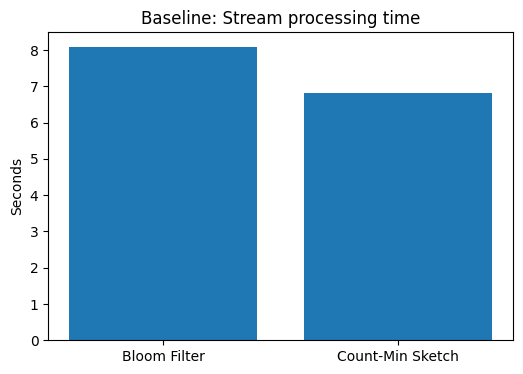

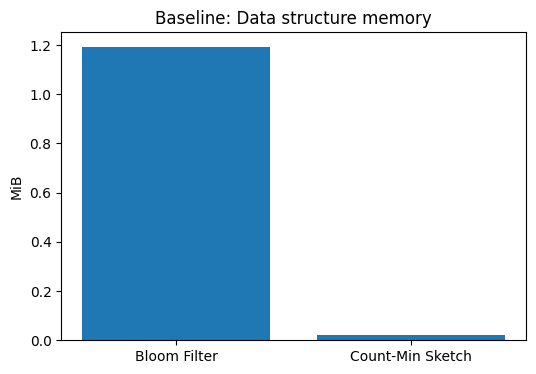

In [10]:
bf_base = bf_df[(bf_df["bits/item"] == 10) & (bf_df["k"] == 7)].iloc[0]
cms_base = cms_df[(cms_df["width"] == 1024) & (cms_df["depth"] == 5)].iloc[0]

compare = pd.DataFrame([
    {
        "알고리즘": "Bloom Filter",
        "처리 대상": "(UserID, MovieID) 존재 여부",
        "기준 파라미터": "10 bits/item, k=7",
        "주요 정확도 지표": f"FPR {bf_base['FPR']:.2%}, FNR {bf_base['FNR']:.2%}",
        "메모리(MiB)": bf_base["메모리(MiB)"],
        "처리시간(초)": bf_base["처리시간(초)"],
        "처리량(건/초)": bf_base["처리량(건/초)"],
    },
    {
        "알고리즘": "Count-Min Sketch",
        "처리 대상": "MovieID별 빈도",
        "기준 파라미터": "width=1024, depth=5",
        "주요 정확도 지표": f"MAPE {cms_base['MAPE(%)']:.2f}%, MAE {cms_base['MAE(건)']:.2f}건",
        "메모리(MiB)": cms_base["메모리(MiB)"],
        "처리시간(초)": cms_base["처리시간(초)"],
        "처리량(건/초)": cms_base["처리량(건/초)"],
    },
])
display(compare)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Bloom Filter", "Count-Min Sketch"], compare["처리시간(초)"])
ax.set(title="Baseline: Stream processing time", ylabel="Seconds")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Bloom Filter", "Count-Min Sketch"], compare["메모리(MiB)"])
ax.set(title="Baseline: Data structure memory", ylabel="MiB")
plt.show()

**STEP 06. 실험 결론**

In [11]:
lowest_bf_fpr = bf_df.sort_values(["FPR", "메모리(MiB)"]).iloc[0]
lowest_cms_mape = cms_df.sort_values(["MAPE(%)", "메모리(MiB)"]).iloc[0]

print("=" * 72)
print("[1] 데이터 및 실험 환경")
print(f"평점 데이터: {record_count:,}개 / 영화: {len(movie_truth):,}개")
print(f"Bloom Filter 음성 평가 표본: {len(negative_samples):,}개")
print("매개변수별 처리시간은 각 설정의 ZIP 재읽기 + 갱신 시간을 포함")

print("\n[2] Bloom Filter 결과")
print(f"기준(10 bits/item, k=7): FPR={bf_base['FPR']:.2%}, "
      f"FN={int(bf_base['FN 개수'])}, 메모리={bf_base['메모리(MiB)']:.3f} MiB, "
      f"처리시간={bf_base['처리시간(초)']:.2f}초")
print(f"시험 설정 중 최소 FPR: {lowest_bf_fpr['설정']} / "
      f"FPR={lowest_bf_fpr['FPR']:.2%}")

print("\n[3] Count-Min Sketch 결과")
print(f"기준(width=1024, depth=5): MAPE={cms_base['MAPE(%)']:.2f}%, "
      f"MAE={cms_base['MAE(건)']:.2f}건, "
      f"WAPE={cms_base['WAPE(%)']:.2f}%, "
      f"메모리={cms_base['메모리(MiB)']:.3f} MiB, "
      f"처리시간={cms_base['처리시간(초)']:.2f}초")
print(f"시험 설정 중 최소 MAPE: {lowest_cms_mape['설정']} / "
      f"MAPE={lowest_cms_mape['MAPE(%)']:.2f}%")

print("\n[4] 결론")
print("- Bloom Filter는 집합 포함 여부를 근사적으로 검사하며, 삽입한 원소에 대해")
print("  False Negative가 없는 점을 확인했다. FPR은 해시 수와 비트 수에 따라 달라진다.")
print("- Count-Min Sketch는 영화별 빈도를 정확한 값 이상으로 추정하며, width·depth")
print("  조절에 따라 충돌 오차, 자료구조 크기, 처리시간 간의 절충 관계가 나타난다.")
print("- 두 알고리즘 모두 100만 개 수준의 원본 평점 레코드를 통째로 RAM에 저장하지")
print("  않고 입력 한 줄씩 처리할 수 있다.")
print("=" * 72)

# 결과표가 필요하면 CSV로 저장 및 Colab 왼쪽 '파일' 탭에서 다운로드
OUTPUT_DIR = Path(os.environ.get("ML1M_OUTPUT_DIR", "/content"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
bf_df.to_csv(OUTPUT_DIR / "ml1m_bloom_results.csv", index=False, encoding="utf-8-sig")
cms_df.to_csv(OUTPUT_DIR / "ml1m_cms_results.csv", index=False, encoding="utf-8-sig")
compare.to_csv(OUTPUT_DIR / "ml1m_baseline_comparison.csv", index=False, encoding="utf-8-sig")
print(f"실험 결과 CSV 저장 위치: {OUTPUT_DIR}")

[1] 데이터 및 실험 환경
평점 데이터: 1,000,209개 / 영화: 3,706개
Bloom Filter 음성 평가 표본: 10,000개
매개변수별 처리시간은 각 설정의 ZIP 재읽기 + 갱신 시간을 포함

[2] Bloom Filter 결과
기준(10 bits/item, k=7): FPR=0.80%, FN=0, 메모리=1.192 MiB, 처리시간=8.09초
시험 설정 중 최소 FPR: BF: 14bit / k7 / FPR=0.12%

[3] Count-Min Sketch 결과
기준(width=1024, depth=5): MAPE=1348.80%, MAE=199.37건, WAPE=73.87%, 메모리=0.020 MiB, 처리시간=6.81초
시험 설정 중 최소 MAPE: CMS: w4096 / d5 / MAPE=15.33%

[4] 결론
- Bloom Filter는 집합 포함 여부를 근사적으로 검사하며, 삽입한 원소에 대해
  False Negative가 없는 점을 확인했다. FPR은 해시 수와 비트 수에 따라 달라진다.
- Count-Min Sketch는 영화별 빈도를 정확한 값 이상으로 추정하며, width·depth
  조절에 따라 충돌 오차, 자료구조 크기, 처리시간 간의 절충 관계가 나타난다.
- 두 알고리즘 모두 100만 개 수준의 원본 평점 레코드를 통째로 RAM에 저장하지
  않고 입력 한 줄씩 처리할 수 있다.
실험 결과 CSV 저장 위치: /content
